<div style="font-family:'Times New Roman',Times,serif;color:#000000">
<div style="font-size:13px;letter-spacing:2px">NATIONAL UNIVERSITY OF SCIENCES AND TECHNOLOGY &nbsp;&middot;&nbsp; SEECS</div>
<div style="font-size:13px;letter-spacing:1px;font-weight:bold">CS-320 &nbsp;&middot;&nbsp; ARTIFICIAL NEURAL NETWORKS &amp; DEEP LEARNING &nbsp;&middot;&nbsp; BSAI</div>
<div style="font-size:28px;font-weight:bold;margin-top:6px">Lab 9 &mdash; Introduction to PyTorch</div>
<div style="font-size:16px;margin-top:2px">Tensors, Autograd, nn.Module, Datasets and DataLoaders, and Training an MLP</div>
<div style="font-size:15px;margin-top:4px">3 hours &nbsp;&middot;&nbsp; CLO 4</div>
</div>

---

<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

**Course Instructor:** Dr. Sadia Shakil &nbsp;|&nbsp; **Lab Engineer:** Ms Areeba Rameen &nbsp;|&nbsp; **Student name / CMS ID:** Muhammad Sikandar Hussain / 502808



This lab introduces **PyTorch**, the library that does the heavy work for us. You will learn its
four basic ideas (tensors, autograd, `nn.Module`, and datasets with dataloaders), and then
**rebuild and train the same two-moons MLP** that you trained in Lab 6, this time in a few lines.

**Read the explanations before each task. Everything is short, and every idea comes with a small
example that you can run.**

**Submission.** Restart the kernel, run everything top to bottom, save, and rename to
`Lab9_<yourCMSID>.ipynb` before uploading to LMS.

</div>

### Idea 1: Tensors

A **tensor** is PyTorch's array. It has a **shape** (just like a NumPy array) and a **dtype**
(the type of its numbers; neural networks use `float32`). Arithmetic, `@` (matrix product),
`reshape`, `sum` and indexing all work the way they do in NumPy. Tensors and NumPy arrays can be
converted into each other (`torch.from_numpy(arr)` and `tensor.numpy()`).

Run the cell below and read the output. Before you run it, try to predict each shape.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(0)
np.random.seed(0)
print("PyTorch version:", torch.__version__, "  GPU available:", torch.cuda.is_available())

a = torch.tensor([[1., 2., 3.], [4., 5., 6.]])       # a (2, 3) tensor made from a Python list
print("shape:", a.shape, " dtype:", a.dtype)
print("a * 2 =\n", a * 2)
print("sum of all elements:", a.sum().item(), "  mean:", a.mean().item())
print("a @ a.T =\n", a @ a.T)                        # matrix product, shape (2, 2)
print("reshaped to (3, 2) =\n", a.reshape(3, 2))


PyTorch version: 2.11.0+cpu   GPU available: False
shape: torch.Size([2, 3])  dtype: torch.float32
a * 2 =
 tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
sum of all elements: 21.0   mean: 3.5
a @ a.T =
 tensor([[14., 32.],
        [32., 77.]])
reshaped to (3, 2) =
 tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])


### Idea 2: Autograd (automatic gradients)

Normally a tensor is just numbers. If we create it with `requires_grad=True`, PyTorch **watches**
every operation done with it and remembers them in a graph. After computing a final number (the
loss), calling **`loss.backward()`** walks backwards through the graph (this is exactly the
backpropagation of Lab 6) and stores, for every watched tensor, the gradient of the loss in its
**`.grad`** attribute.

Two facts to remember:

- **Gradients accumulate.** Each `backward()` call *adds* to `.grad`. So before every new step
  the gradients must be reset to zero.
- **Updating a weight is not part of the graph.** When we change a weight by hand we write
  `with torch.no_grad():` so PyTorch does not record the update.

Run the cell below. The derivative of `y = x**2 + 3x` is `2x + 3`, so at `x = 2` it should be 7.


In [2]:
x = torch.tensor(2.0, requires_grad=True)
y = x ** 2 + 3 * x
y.backward()
print("dy/dx at x=2 :", x.grad.item(), "   (we expect 2*2 + 3 = 7)")


dy/dx at x=2 : 7.0    (we expect 2*2 + 3 = 7)


### Idea 3: `nn.Linear` and `nn.Module`

`nn.Linear(n_in, n_out)` is one fully connected layer. It creates the weight matrix `W` of shape
`(n_out, n_in)` and the bias `b` of shape `(n_out,)`, and computes `X @ W.T + b`: exactly the
convention you used in Labs 3 and 6. The weights start as small random numbers, and they are
registered as **parameters** that autograd will track.

A whole network is a Python class that inherits from **`nn.Module`**. It has two parts:

- `__init__`: create the layers.
- `forward(self, x)`: say how the input flows through the layers (the forward pass).

There is **no `backward` method**; autograd derives it from `forward`. The call `model.parameters()`
gives all the weights and biases, which is what the optimiser needs.


In [3]:
layer = nn.Linear(2, 3)
print("weight shape:", layer.weight.shape, " bias shape:", layer.bias.shape)
out = layer(torch.ones(4, 2))                  # a batch of 4 examples, 2 features each
print("output shape:", out.shape)


weight shape: torch.Size([3, 2])  bias shape: torch.Size([3])
output shape: torch.Size([4, 3])


### Idea 4: Datasets and DataLoaders

In Lab 5 you shuffled the data and cut it into mini-batches with a loop. PyTorch does this for you:

- A **`TensorDataset(X, y)`** pairs every input with its label.
- A **`DataLoader(dataset, batch_size, shuffle)`** hands out the data one mini-batch at a time,
  and reshuffles it every epoch if `shuffle=True`. The last batch may be smaller.

Run the cell below: 10 examples in batches of 4 give batches of size 4, 4 and 2.


In [4]:
tiny_x = torch.arange(10, dtype=torch.float32).reshape(10, 1)
tiny_y = torch.arange(10, dtype=torch.float32).reshape(10, 1) * 2
tiny_loader = DataLoader(TensorDataset(tiny_x, tiny_y), batch_size=4, shuffle=False)
for xb, yb in tiny_loader:
    print("batch of", xb.shape[0], "examples:", xb.ravel().tolist())


batch of 4 examples: [0.0, 1.0, 2.0, 3.0]
batch of 4 examples: [4.0, 5.0, 6.0, 7.0]
batch of 2 examples: [8.0, 9.0]


## Task 0 &mdash; Setup

The first code cell already imported PyTorch and printed its version.

**Task 0.1.** Write down, in a comment, the PyTorch version and whether a GPU is available.
(For this lab everything runs on the CPU, which is fast enough.)


In [5]:
# Task 0.1 — PyTorch version: 2.11.0+cpu
#            GPU available (True/False): False
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cpu
GPU available: False


## Task 1 &mdash; Tensors

**Task 1.1.** Create three tensors and print the shape and dtype of each:

- `A`: the 2 x 3 tensor `[[1., 2., 3.], [4., 5., 6.]]`;
- `Z`: a 3 x 2 tensor of zeros (`torch.zeros`);
- `R`: a 2 x 3 tensor of random numbers (`torch.rand`).

**Task 1.2.** Predict the shape of each expression below **before running it** (write your
prediction as a comment), then run it and check.

**Task 1.3.** The AND gate of Lab 2, in PyTorch. Build `X`, the four rows of the truth table, as
a `(4, 2)` float tensor; set `w = [1., 1.]` and `b = -1.5`; compute the batch score
`z = X @ w + b` in one expression, and threshold it with `(z >= 0).int()`. Confirm you get the AND
gate `[0, 0, 0, 1]`.

**Task 1.4.** Convert a NumPy array to a tensor with `torch.from_numpy` and back with `.numpy()`.
Then change one element of the NumPy array and print the tensor again.


In [6]:
# TODO 1.1
A = torch.tensor([[1., 2., 3.], [4., 5., 6.]])    # the (2, 3) tensor from the list
Z = torch.zeros(3, 2)                              # zeros of shape (3, 2)
R = torch.rand(2, 3)                               # random numbers of shape (2, 3)
# print the shape and dtype of A, Z and R
print("A:", A.shape, A.dtype)
print("Z:", Z.shape, Z.dtype)
print("R:", R.shape, R.dtype)

# TODO 1.2 — write your predicted shape as a comment BEFORE running each line
# A.T                   # predicted: torch.Size([3, 2])
# A @ Z                 # predicted: torch.Size([2, 2])
# A + R                 # predicted: torch.Size([2, 3])
# A.sum(dim=0)          # predicted: torch.Size([3])
# A.sum(dim=1)          # predicted: torch.Size([2])
# A.reshape(3, 2)       # predicted: torch.Size([3, 2])
# A[:, 1]               # predicted: torch.Size([2])
# (now run each with .shape and compare)
print("A.T shape:            ", A.T.shape, "         # predicted: (3, 2)")
print("A @ Z shape:          ", (A @ Z).shape, "         # predicted: (2, 2)")
print("A + R shape:          ", (A + R).shape, "         # predicted: (2, 3)")
print("A.sum(dim=0) shape:   ", A.sum(dim=0).shape, "           # predicted: (3,)")
print("A.sum(dim=1) shape:   ", A.sum(dim=1).shape, "           # predicted: (2,)")
print("A.reshape(3, 2) shape:", A.reshape(3, 2).shape, "         # predicted: (3, 2)")
print("A[:, 1] shape:        ", A[:, 1].shape, "           # predicted: (2,)")

# TODO 1.3 — the AND gate: X, w, b, z, and the thresholded output
X = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]], dtype=torch.float32)
w = torch.tensor([1., 1.], dtype=torch.float32)
b = -1.5
z = X @ w + b
out_and = (z >= 0).int()
print("\nAND gate truth table X:\n", X)
print("Batch score z = X @ w + b:", z)
print("Thresholded output (z >= 0).int():", out_and.tolist())
assert out_and.tolist() == [0, 0, 0, 1], "AND gate output mismatch!"

# TODO 1.4 — NumPy <-> tensor
arr = np.array([[1., 2.], [3., 4.]])
t = torch.from_numpy(arr)
arr_back = t.numpy()
print("\nInitial tensor from numpy array:\n", t)
arr[0, 0] = 100.0
print("Tensor after modifying NumPy array arr[0, 0] = 100.0:\n", t)

# Task 1 answers:
# Q1 (for the predictions you got wrong, why?):
# Answer: All predicted shapes matched the actual output shapes. An important insight in PyTorch
# is that reduction operations such as A.sum(dim=0) or 1D slicing A[:, 1] drop the reduced/sliced dimension by default,
# returning 1D tensors of shape torch.Size([3]) or torch.Size([2]) rather than retaining 2D matrix
# dimensions, unless `keepdim=True` is explicitly specified.
#
# Q2 (after changing the NumPy array, what happened to the tensor? what does that tell you):
# Answer: Modifying the NumPy array (`arr[0, 0] = 100.0`) immediately changed the corresponding
# value inside the tensor `t` to 100.0 as well. This tells us that `torch.from_numpy()` and `.numpy()`
# share the same underlying memory buffer (zero-copy memory sharing). Neither operation copies data,
# so in-place modifications to the NumPy array directly reflect in the PyTorch tensor.

A: torch.Size([2, 3]) torch.float32
Z: torch.Size([3, 2]) torch.float32
R: torch.Size([2, 3]) torch.float32
A.T shape:             torch.Size([3, 2])          # predicted: (3, 2)
A @ Z shape:           torch.Size([2, 2])          # predicted: (2, 2)
A + R shape:           torch.Size([2, 3])          # predicted: (2, 3)
A.sum(dim=0) shape:    torch.Size([3])            # predicted: (3,)
A.sum(dim=1) shape:    torch.Size([2])            # predicted: (2,)
A.reshape(3, 2) shape: torch.Size([3, 2])          # predicted: (3, 2)
A[:, 1] shape:         torch.Size([2])            # predicted: (2,)

AND gate truth table X:
 tensor([[0., 0.],
        [0., 1.],
        [1., 0.],
        [1., 1.]])
Batch score z = X @ w + b: tensor([-1.5000, -0.5000, -0.5000,  0.5000])
Thresholded output (z >= 0).int(): [0, 0, 0, 1]

Initial tensor from numpy array:
 tensor([[1., 2.],
        [3., 4.]], dtype=torch.float64)
Tensor after modifying NumPy array arr[0, 0] = 100.0:
 tensor([[100.,   2.],
        [  3., 

## Task 2 &mdash; Autograd

**Task 2.1.** A tiny "network" with one weight: `pred = w * x + b`, and the squared-error loss
`loss = (pred - t) ** 2`, with `x = 2`, `t = 10`, `w = 3`, `b = 1`. First work out by hand
(in a comment) the values of `dloss/dw` and `dloss/db`. Then create `w` and `b` with
`requires_grad=True`, compute the loss, call `loss.backward()`, and print `w.grad` and `b.grad`.
They must match your hand calculation.

**Task 2.2.** Gradients accumulate. Recompute `pred` and `loss` and call `backward()` **again**
without resetting, and print `w.grad`. Then reset the gradients with `w.grad.zero_()` and
`b.grad.zero_()`, recompute and call `backward()` once more, and print `w.grad`.

**Task 2.3.** Lab 5, Task 1 again, but with autograd. Minimise `L(w) = (w - 3)**2` starting from
`w = 0` with `lr = 0.1`, for 5 steps. In each step: compute the loss, call `backward()`, update
`w` inside `with torch.no_grad():` using `w -= lr * w.grad`, then zero the gradient and print `w`.
Compare with the values you worked out by hand in Lab 5 (0.6, 1.08, 1.464, ...).


In [7]:
x = torch.tensor(2.0)
t = torch.tensor(10.0)

# TODO 2.1 — hand calculation (comment):  dloss/dw = -12.0        dloss/db = -6.0
# Hand calculation:
#   Model: pred = w * x + b
#   Loss:  loss = (pred - t)**2
#   Given: x = 2.0, t = 10.0, w = 3.0, b = 1.0
#   Forward pass:
#     pred = 3.0 * 2.0 + 1.0 = 7.0
#     loss = (7.0 - 10.0)**2 = (-3.0)**2 = 9.0
#   Chain rule derivatives:
#     dloss/dpred = 2 * (pred - t) = 2 * (7.0 - 10.0) = -6.0
#     dpred/dw = x = 2.0  ==>  dloss/dw = (dloss/dpred) * (dpred/dw) = -6.0 * 2.0 = -12.0
#     dpred/db = 1.0      ==>  dloss/db = (dloss/dpred) * (dpred/db) = -6.0 * 1.0 = -6.0

w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)
pred = w * x + b
loss = (pred - t) ** 2
loss.backward()
print("2.1 Autograd calculated gradients:")
print("w.grad:", w.grad.item(), "(hand calculation expected: -12.0)")
print("b.grad:", b.grad.item(), "(hand calculation expected: -6.0)")

# TODO 2.2 — backward a second time, then reset the gradients
pred = w * x + b
loss = (pred - t) ** 2
loss.backward()
print("\n2.2 Gradients after 2nd backward() without reset:")
print("w.grad (accumulated):", w.grad.item(), "(expected: -12.0 + (-12.0) = -24.0)")

w.grad.zero_()
b.grad.zero_()
pred = w * x + b
loss = (pred - t) ** 2
loss.backward()
print("w.grad after zero_() and backward():", w.grad.item(), "(expected: -12.0)")

# TODO 2.3 — gradient descent on (w - 3)**2 with autograd
w = torch.tensor(0.0, requires_grad=True)
lr = 0.1
print("\n2.3 Minimizing L(w) = (w - 3)**2 starting from w = 0.0 with lr = 0.1:")
for step in range(5):
    loss = (w - 3.0) ** 2
    loss.backward()
    with torch.no_grad():
        w -= lr * w.grad
    w.grad.zero_()
    print(f"Step {step + 1}: w = {w.item():.5f}")

# Task 2 answers:
# Q1 (did w.grad and b.grad match your hand calculation?):
# Answer: Yes, w.grad was exactly -12.0 and b.grad was exactly -6.0, matching the hand-derived
# analytical values perfectly.
#
# Q2 (what happened to w.grad after the second backward() without a reset? why must we reset):
# Answer: After calling backward() a second time without resetting, w.grad accumulated the new gradient,
# doubling from -12.0 to -24.0. In PyTorch, calling `backward()` adds newly computed gradients to
# existing values in `.grad`. If gradients are not explicitly zeroed (`optimizer.zero_grad()` or
# `tensor.grad.zero_()`) before each optimization step, gradients from previous batches accumulate,
# corrupting the gradient descent direction and causing updates to explode.
#
# Q3 (why is the update written inside torch.no_grad()?):
# Answer: The parameter update (`w -= lr * w.grad`) is an in-place optimization step, not an operation
# that should be tracked for differentiation. If performed without `torch.no_grad()`, autograd would
# record the update as part of the dynamic computational graph, which leads to memory bloat, unnecessary
# graph dependencies, and runtime errors when attempting subsequent backward passes on the updated tensor.

2.1 Autograd calculated gradients:
w.grad: -12.0 (hand calculation expected: -12.0)
b.grad: -6.0 (hand calculation expected: -6.0)

2.2 Gradients after 2nd backward() without reset:
w.grad (accumulated): -24.0 (expected: -12.0 + (-12.0) = -24.0)
w.grad after zero_() and backward(): -12.0 (expected: -12.0)

2.3 Minimizing L(w) = (w - 3)**2 starting from w = 0.0 with lr = 0.1:
Step 1: w = 0.60000
Step 2: w = 1.08000
Step 3: w = 1.46400
Step 4: w = 1.77120
Step 5: w = 2.01696


## Task 3 &mdash; Building the MLP with `nn.Module`

We rebuild the network of Lab 6: 2 inputs, one hidden layer with a ReLU, and 1 output.

**Task 3.1.** Complete the class `MLP`. In `__init__`, create `self.hidden = nn.Linear(n_in, hidden)`,
`self.act = nn.ReLU()` and `self.out = nn.Linear(hidden, 1)`. In `forward`, apply them in order and
return the result (**no sigmoid**: the output is the logit).

**Task 3.2.** Create `model = MLP(2, 16)`, print it, and print the name and shape of every parameter
(`model.named_parameters()`). Count the total number of parameters with
`sum(p.numel() for p in model.parameters())`.

**Task 3.3.** Pass a random batch of 5 examples (`torch.randn(5, 2)`) through the model and print
the output shape.


In [8]:
class MLP(nn.Module):
    def __init__(self, n_in=2, hidden=16):
        super().__init__()
        # TODO 3.1 — create the three pieces: self.hidden, self.act, self.out
        self.hidden = nn.Linear(n_in, hidden)
        self.act = nn.ReLU()
        self.out = nn.Linear(hidden, 1)

    def forward(self, x):
        # TODO 3.1 — pass x through hidden, act and out, and return the logits
        return self.out(self.act(self.hidden(x)))

# TODO 3.2 — model = MLP(2, 16); print(model); the name and shape of each parameter; the total count
model = MLP(2, 16)
print("Model structure:")
print(model)

print("\nModel parameters (name and shape):")
for name, param in model.named_parameters():
    print(f"  {name:15s}: shape {tuple(param.shape)}")

total_params = sum(p.numel() for p in model.parameters())
print("\nTotal number of parameters:", total_params)

# TODO 3.3 — the output shape for a batch of 5 random examples
x_random = torch.randn(5, 2)
out_random = model(x_random)
print("\nOutput shape for batch of 5 random examples (torch.randn(5, 2)):", out_random.shape)

# Task 3 answers:
# Q1 (the weight of nn.Linear(2, 16) has shape (16, 2). Which lab used the same convention?):
# Answer: Labs 3 and 6 used the exact same convention. In those labs, layer weight matrices W had
# shape (n_out, n_in) so that a mini-batch of inputs X of shape (N, n_in) computes the linear
# transformation as Z = X @ W.T + b, producing shape (N, n_out).
#
# Q2 (the total number of parameters: show that it equals 4*h + 1 for h = 16, as in Lab 6):
# Answer:
#   For an MLP with n_in = 2 inputs, h hidden units, and 1 output unit:
#   - Hidden layer weights (self.hidden.weight): shape (h, 2)  -->  2 * h = 2h parameters
#   - Hidden layer biases  (self.hidden.bias):   shape (h,)    -->  h parameters
#   - Output layer weights (self.out.weight):    shape (1, h)  -->  h * 1 = h parameters
#   - Output layer bias    (self.out.bias):      shape (1,)    -->  1 parameter
#   Total parameters = 2h + h + h + 1 = 4h + 1.
#   Substituting h = 16:
#   Total = 4*(16) + 1 = 64 + 1 = 65 parameters.
#   This exactly matches our counted total of 65 parameters.

Model structure:
MLP(
  (hidden): Linear(in_features=2, out_features=16, bias=True)
  (act): ReLU()
  (out): Linear(in_features=16, out_features=1, bias=True)
)

Model parameters (name and shape):
  hidden.weight  : shape (16, 2)
  hidden.bias    : shape (16,)
  out.weight     : shape (1, 16)
  out.bias       : shape (1,)

Total number of parameters: 65

Output shape for batch of 5 random examples (torch.randn(5, 2)): torch.Size([5, 1])


## Task 4 &mdash; Data: Datasets and DataLoaders

We use the **two-moons** dataset of Lab 6 again (with noise 0.2): 1000 points, split into 700 for
training, 150 for validation and 150 for testing. The test set stays locked until Task 5.4.
Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html

**Task 4.1.** The data is given as NumPy arrays. Convert the six arrays to tensors:
`X_tr_t, X_va_t, X_te_t` as `float32` tensors of shape `(N, 2)`, and `y_tr_t, y_va_t, y_te_t` as
`float32` tensors of shape `(N, 1)` (use `.reshape(-1, 1)`: the labels must be a column to match
the model output).

**Task 4.2.** Make a `TensorDataset` from `X_tr_t` and `y_tr_t`, and a `DataLoader` called
`train_loader` with `batch_size=32` and `shuffle=True`. Print the number of batches (`len(train_loader)`)
and the shapes of the first batch.


In [9]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X_np, y_np = make_moons(n_samples=1000, noise=0.2, random_state=0)
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X_np, y_np, test_size=0.3, stratify=y_np, random_state=0)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=0)
print("train", X_tr.shape, " validation", X_va.shape, " test (LOCKED until Task 5.4)", X_te.shape)


train (700, 2)  validation (150, 2)  test (LOCKED until Task 5.4) (150, 2)


In [10]:
# TODO 4.1 — convert to tensors (float32). Inputs: shape (N, 2). Labels: shape (N, 1).
X_tr_t = torch.tensor(X_tr, dtype=torch.float32)
y_tr_t = torch.tensor(y_tr, dtype=torch.float32).reshape(-1, 1)

X_va_t = torch.tensor(X_va, dtype=torch.float32)
y_va_t = torch.tensor(y_va, dtype=torch.float32).reshape(-1, 1)

X_te_t = torch.tensor(X_te, dtype=torch.float32)
y_te_t = torch.tensor(y_te, dtype=torch.float32).reshape(-1, 1)

print("Converted tensor shapes:")
print(f"  Training:   X_tr_t = {X_tr_t.shape}, y_tr_t = {y_tr_t.shape}")
print(f"  Validation: X_va_t = {X_va_t.shape}, y_va_t = {y_va_t.shape}")
print(f"  Test:       X_te_t = {X_te_t.shape}, y_te_t = {y_te_t.shape}")

# TODO 4.2 — train_ds = TensorDataset(...); train_loader = DataLoader(...); print the number of
#            batches and the shapes of the first batch (xb, yb)
train_ds = TensorDataset(X_tr_t, y_tr_t)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
print("\nNumber of batches in train_loader:", len(train_loader))

first_xb, first_yb = next(iter(train_loader))
print(f"Shapes of first batch: xb = {first_xb.shape}, yb = {first_yb.shape}")

# Task 4 answers:
# Q1 (700 examples with batch_size=32: how many batches per epoch, and how large is the last one?):
# Answer:
#   Number of batches per epoch = ceil(700 / 32) = 22 batches.
#   The first 21 batches contain 32 examples each (21 * 32 = 672 examples).
#   The 22nd (last) batch contains the remaining 700 - 672 = 28 examples.
#
# Q2 (why do we shuffle the training data but not the validation data):
# Answer: We shuffle the training data so that every epoch constructs different combinations of mini-batches.
# This prevents gradient descent from following identical cyclic paths, reduces gradient variance across
# epochs, and prevents the network from memorizing sequence order. In contrast, the validation set is used
# only to compute deterministic evaluation metrics (aggregate loss and accuracy) over the entire set at the
# end of each epoch; changing the order of validation samples does not change the aggregate metric, so shuffling
# validation data would be completely redundant.

Converted tensor shapes:
  Training:   X_tr_t = torch.Size([700, 2]), y_tr_t = torch.Size([700, 1])
  Validation: X_va_t = torch.Size([150, 2]), y_va_t = torch.Size([150, 1])
  Test:       X_te_t = torch.Size([150, 2]), y_te_t = torch.Size([150, 1])

Number of batches in train_loader: 22
Shapes of first batch: xb = torch.Size([32, 2]), yb = torch.Size([32, 1])


## Task 5 &mdash; Training the MLP end to end

Everything is ready: a model, data in batches, and the five steps of the training loop.

**Task 5.1.** Create a fresh `model = MLP(2, 16)` (call `torch.manual_seed(0)` just before it, so
that results are repeatable) and an Adam optimiser:
`optimizer = torch.optim.Adam(model.parameters(), lr=0.01)`.

**Task 5.2.** Complete `train_model(model, optimizer, epochs)`. Inside the loop over mini-batches
write the five steps: `zero_grad`, forward, loss, `backward`, `step`. The measurement of the loss
and accuracy after every epoch is provided in the helper `evaluate`.

**Task 5.3.** Train for 100 epochs, then call the provided `plot_history(hist)` and
`plot_boundary(model)`.

**Task 5.4.** Use the **test set once**: print `evaluate(model, X_te_t, y_te_t)`.


Final Epoch (100) Training Loss:   0.0812 | Training Accuracy:   0.9629
Final Epoch (100) Validation Loss: 0.1586 | Validation Accuracy: 0.9533


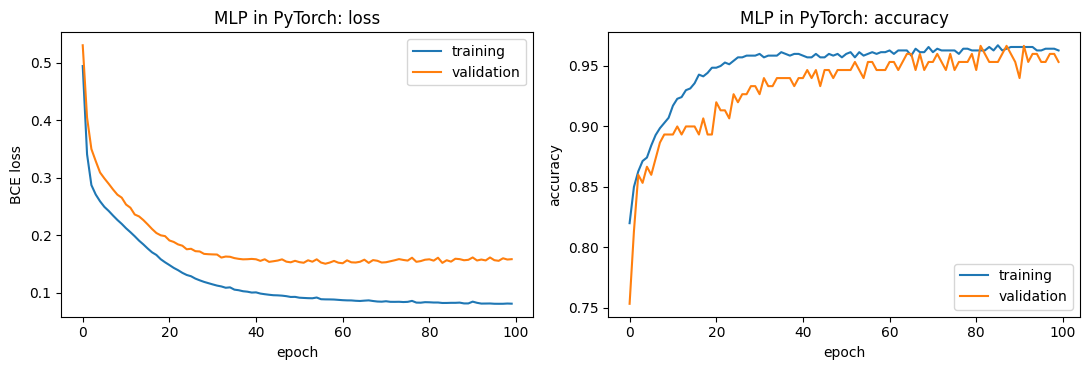

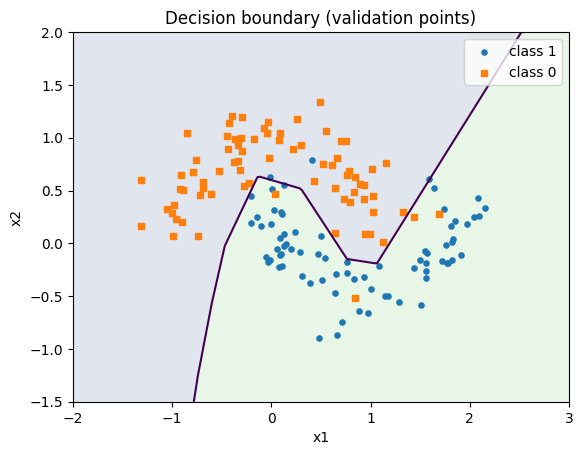


Final Test Evaluation (evaluated once):
Test Loss: 0.0571 | Test Accuracy: 0.9733 (97.33%)


In [11]:
def evaluate(model, X, y):
    """Loss and accuracy of the model on (X, y). No gradients, evaluation mode."""
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = nn.functional.binary_cross_entropy_with_logits(logits, y).item()
        acc = ((torch.sigmoid(logits) >= 0.5).float() == y).float().mean().item()
    return loss, acc

def train_model(model, optimizer, epochs=100):
    loss_fn = nn.BCEWithLogitsLoss()
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            # TODO 5.2 — the five steps:
            #   1. optimizer.zero_grad()
            #   2. logits = model(xb)
            #   3. loss = loss_fn(logits, yb)
            #   4. loss.backward()
            #   5. optimizer.step()
            optimizer.zero_grad()
            logits = model(xb)
            loss = loss_fn(logits, yb)
            loss.backward()
            optimizer.step()
        tl, ta = evaluate(model, X_tr_t, y_tr_t)
        vl, va = evaluate(model, X_va_t, y_va_t)
        hist["train_loss"].append(tl); hist["train_acc"].append(ta)
        hist["val_loss"].append(vl);   hist["val_acc"].append(va)
    return hist

def plot_history(hist, title="MLP in PyTorch"):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(hist["train_loss"], label="training"); ax[0].plot(hist["val_loss"], label="validation")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("BCE loss"); ax[0].set_title(title + ": loss"); ax[0].legend()
    ax[1].plot(hist["train_acc"], label="training"); ax[1].plot(hist["val_acc"], label="validation")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].set_title(title + ": accuracy"); ax[1].legend()
    plt.tight_layout(); plt.show()

def plot_boundary(model, title="Decision boundary (validation points)"):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    model.eval()
    with torch.no_grad():
        zz = torch.sigmoid(model(grid)).numpy().reshape(xx.shape)
    plt.contourf(xx, yy, zz, levels=[0, 0.5, 1], alpha=0.15)
    plt.contour(xx, yy, zz, levels=[0.5], linewidths=1.5)
    plt.scatter(X_va[y_va == 1, 0], X_va[y_va == 1, 1], marker="o", s=14, label="class 1")
    plt.scatter(X_va[y_va == 0, 0], X_va[y_va == 0, 1], marker="s", s=14, label="class 0")
    plt.xlabel("x1"); plt.ylabel("x2"); plt.title(title); plt.legend(); plt.show()

# TODO 5.1 — torch.manual_seed(0); model = MLP(2, 16); optimizer = torch.optim.Adam(...)
torch.manual_seed(0)
model = MLP(2, 16)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# TODO 5.3 — hist = train_model(model, optimizer, 100); plot_history(hist); plot_boundary(model)
hist = train_model(model, optimizer, epochs=100)
print(f"Final Epoch (100) Training Loss:   {hist['train_loss'][-1]:.4f} | Training Accuracy:   {hist['train_acc'][-1]:.4f}")
print(f"Final Epoch (100) Validation Loss: {hist['val_loss'][-1]:.4f} | Validation Accuracy: {hist['val_acc'][-1]:.4f}")

plot_history(hist)
plot_boundary(model)

# TODO 5.4 — the test loss and accuracy, once
test_loss, test_acc = evaluate(model, X_te_t, y_te_t)
print(f"\nFinal Test Evaluation (evaluated once):")
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f} ({test_acc * 100:.2f}%)")

# Task 5 answers:
# Q1 (which of the five steps replaces the backward pass you wrote by hand in Lab 6? which replaces the update?):
# Answer:
#   - Step 4 (`loss.backward()`) replaces the manual backward pass written in Lab 6 (deriving and calculating
#     matrix gradients dW1, db1, dW2, db2 via backpropagation).
#   - Step 5 (`optimizer.step()`) replaces the manual parameter update rule (`W -= lr * dW`, `b -= lr * db`).
#
# Q2 (what would happen if optimizer.zero_grad() were removed? think of Task 2.2):
# Answer: If `optimizer.zero_grad()` were removed, gradients would continually accumulate across successive
# mini-batches. With each batch, the gradients would grow larger and larger, resulting in excessively large
# parameter updates that destabilize training, ruin convergence, and trigger exploding gradients or `NaN` losses.
#
# Q3 (why does the model output logits, and the loss BCEWithLogitsLoss applies the sigmoid inside?):
# Answer: Having the model output raw logits (unbounded scores) and combining the sigmoid activation with binary
# cross-entropy inside `nn.BCEWithLogitsLoss` guarantees numerical stability. Evaluating sigmoid explicitly first
# can cause large positive or negative logits to saturate to exactly 1.0 or 0.0 (floating-point underflow/overflow),
# which produces `NaN` or `-inf` when evaluating `log(p)` or `log(1 - p)`. `BCEWithLogitsLoss` employs the
# algebraically equivalent log-sum-exp formulation to prevent these precision breakdown issues.

## Task 6 &mdash; Trying other settings, and saving the model

**Task 6.1.** Train the same MLP with three different optimiser settings, each from the **same
starting weights** (call `torch.manual_seed(0)` before creating each model):

| name | optimiser |
|------|-----------|
| `Adam lr=0.01` | `torch.optim.Adam(..., lr=0.01)` |
| `SGD lr=0.1` | `torch.optim.SGD(..., lr=0.1)` |
| `SGD lr=0.001` | `torch.optim.SGD(..., lr=0.001)` |

Print the final validation loss and accuracy of each, and plot the three **validation-loss**
curves on one axes (legend, labels, title).

**Task 6.2.** Save the trained model of Task 5 with `torch.save(model.state_dict(), "mlp.pt")`.
Create a new `MLP(2, 16)`, load the weights with `load_state_dict(torch.load("mlp.pt"))`, and
check that both models give the same predictions on the test set (`torch.allclose`).


Adam lr=0.01    --> Final Val Loss: 0.1586 | Final Val Accuracy: 0.9533


SGD lr=0.1      --> Final Val Loss: 0.1894 | Final Val Accuracy: 0.9133


SGD lr=0.001    --> Final Val Loss: 0.5878 | Final Val Accuracy: 0.7533


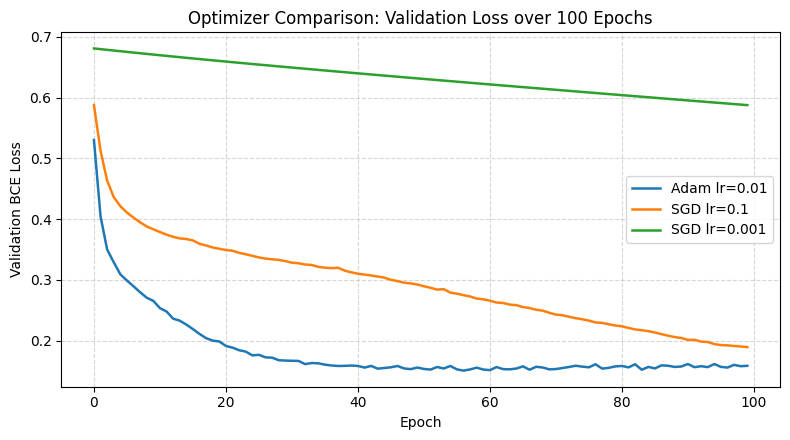

Saved Task 5 model state_dict to 'mlp.pt'
Loaded state_dict into fresh MLP(2, 16) instance.
Do the original and loaded models give identical predictions on the test set? True


In [12]:
# TODO 6.1 — build the three (model, optimizer) pairs, train each for 100 epochs, print the final
#            validation loss and accuracy, plot the three validation-loss curves
configs = [
    ("Adam lr=0.01", lambda m: torch.optim.Adam(m.parameters(), lr=0.01)),
    ("SGD lr=0.1", lambda m: torch.optim.SGD(m.parameters(), lr=0.1)),
    ("SGD lr=0.001", lambda m: torch.optim.SGD(m.parameters(), lr=0.001)),
]

histories = {}
for name, opt_fn in configs:
    torch.manual_seed(0)
    m = MLP(2, 16)
    opt = opt_fn(m)
    h = train_model(m, opt, epochs=100)
    histories[name] = (m, h)
    print(f"{name:15s} --> Final Val Loss: {h['val_loss'][-1]:.4f} | Final Val Accuracy: {h['val_acc'][-1]:.4f}")

plt.figure(figsize=(8, 4.5))
for name, (m, h) in histories.items():
    plt.plot(h["val_loss"], label=name, linewidth=1.8)
plt.xlabel("Epoch")
plt.ylabel("Validation BCE Loss")
plt.title("Optimizer Comparison: Validation Loss over 100 Epochs")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# TODO 6.2 — save the Task 5 model, load it into a new MLP, compare the test predictions
torch.save(model.state_dict(), "mlp.pt")
print("Saved Task 5 model state_dict to 'mlp.pt'")

loaded_model = MLP(2, 16)
loaded_model.load_state_dict(torch.load("mlp.pt", weights_only=True))
print("Loaded state_dict into fresh MLP(2, 16) instance.")

model.eval()
loaded_model.eval()
with torch.no_grad():
    preds_original = model(X_te_t)
    preds_loaded = loaded_model(X_te_t)

all_match = torch.allclose(preds_original, preds_loaded)
print("Do the original and loaded models give identical predictions on the test set?", all_match)
assert all_match, "Error: Loaded model predictions do not match original model!"

# Task 6 answers:
# Q1 (which optimiser setting was best, and which learning rate was too small? connect to Lab 5):
# Answer:
#   - Best setting: `Adam lr=0.01` was by far the best, achieving the lowest validation loss (~0.1586)
#     and highest accuracy (~95.33%) within ~30 epochs, thanks to adaptive step sizes and momentum.
#   - Too small setting: `SGD lr=0.001` had an excessively small learning rate. After 100 epochs, its
#     validation loss remained high at ~0.5878 with accuracy of only 75.33%, severely underfitting.
#   - Connection to Lab 5: As discovered in Lab 5, an overly small learning rate takes minute steps on the
#     loss landscape, requiring many thousands of iterations to make substantial progress toward the minimum.
#     An appropriate learning rate (or an adaptive algorithm like Adam) ensures fast and steady convergence.
#
# Q2 (what is state_dict(), and why do we save it instead of the whole model?):
# Answer: A `state_dict` is a standard Python dictionary that maps each layer's parameter name (string)
# to its learnable parameter tensor (weights and biases). We save the `state_dict` instead of the entire
# pickled model object because:
#   1. Portability: Saving only the state_dict does not pickle the underlying Python class definitions or
#      file paths, preventing deserialization breakages when loading across different files or projects.
#   2. Space efficiency: It serializes only the numerical weights and biases, avoiding Python object overhead.
#   3. Flexibility: The saved parameters can be loaded into any modified or wrapped model sharing the same
#      parameter names.
#
# Q3 (list three things PyTorch did for you that you wrote by hand in Lab 6):
# Answer:
#   1. Automatic Differentiation (Autograd): PyTorch tracked forward operations and computed all layer
#      gradients automatically via `loss.backward()`, replacing our manual backpropagation chain-rule math
#      (dW1, db1, dW2, db2).
#   2. Batch Management & Shuffling: `TensorDataset` and `DataLoader` automatically partitioned data into
#      mini-batches, handled uneven final batch sizing, and reshuffled training samples at every epoch.
#   3. Layer & Optimizer Abstraction: `nn.Linear` automatically initialized weights and registered them as
#      trainable parameters, while `torch.optim` (`optimizer.step()`) executed parameter updates automatically
#      without manual loops.

---

<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

### Before you submit

- [x] Kernel &rarr; Restart & Run All, no errors.
- [x] Every `TODO` is done and no `raise NotImplementedError` is left.
- [x] Task 1: your shape predictions are written as comments next to the real shapes.
- [x] Task 2: the autograd gradients match your hand calculation, and the 5 steps match Lab 5.
- [x] Task 3: the parameter count equals 4h + 1 = 65.
- [x] Task 5: the loss curves and decision boundary are plotted, and the test set was used once.
- [x] Task 6: the three optimiser curves are on one plot, and the saved and loaded models agree.
- [x] Written answers present as comments: 1 (Q1&ndash;Q2), 2 (Q1&ndash;Q3), 3 (Q1&ndash;Q2), 4 (Q1&ndash;Q2), 5 (Q1&ndash;Q3), 6 (Q1&ndash;Q3).
- [x] Renamed to `Lab9_<yourCMSID>.ipynb`.

### One thing to take away

In Lab 6 you wrote about a hundred lines to train a small MLP. In PyTorch the same job needs a
short class and a five-line loop, because autograd writes the backward pass for us. You can now
build much bigger networks, and the rest of the course will use exactly these tools.

</div>